[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


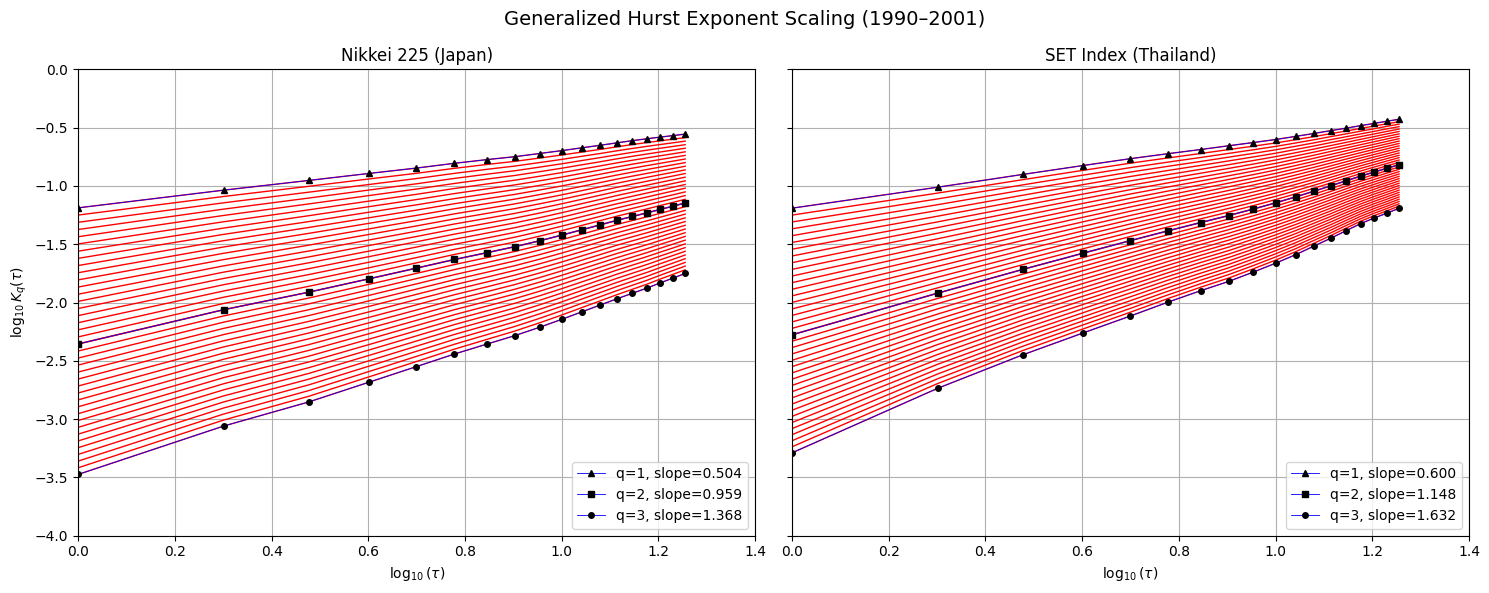

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

taus = np.arange(1, 19)
start = "1990-01-01"
end   = "2001-12-31"

# q ranges
q_low  = np.linspace(1.0, 2.0, 20)
q_high = np.linspace(2.0, 3.0, 20)

# highlight qs
q_highlight = [1, 2, 3]

# highlight color (normalized RGB)
highlight_color = (225/225, 221/225, 187/225)

markets = {
    "Nikkei 225 (Japan)": "^N225",
    "SET Index (Thailand)": "^SET.BK"
}

marker_map = {
    1: "^",   # triangle
    2: "s",   # square
    3: "o"   # circle
}

# axis ranges
X_LIM = (0, 1.4)
Y_LIM = (-4, 0)

# GHE estimator

def generalized_hurst_Kq(log_prices, q, taus):
    X = log_prices.values
    denom = np.mean(np.abs(X) ** q)
    Kq = []

    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Kq.append(np.mean(np.abs(diff) ** q) / denom)

    return np.array(Kq)


fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True, sharex=True)

for ax, (title, ticker) in zip(axes, markets.items()):
    prices = yf.download(ticker, start=start, end=end)["Close"].dropna()
    log_prices = np.log10(prices)
    log_prices -= log_prices.mean()

    # --- q in [1,2]
    for q in q_low:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        ax.plot(np.log10(taus), np.log10(Kq),
                color="red", alpha=1, linewidth=1.0)

    # --- q in [2,3]
    for q in q_high:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        ax.plot(np.log10(taus), np.log10(Kq),
                color="red", alpha=1, linewidth=1.0)
        

    # --- highlight q = 1,2,3 + slope
    for q in q_highlight:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        x = np.log10(taus)
        y = np.log10(Kq)
        
        slope, _, _, _, _ = linregress(x, y)
        
        ax.plot(
        x, y,
        marker=marker_map[q],
        linestyle="-",
        linewidth=0.6,
        markersize=4,
        markerfacecolor="black",
        markeredgecolor="black",
        color="blue",
        label=f"q={q}, slope={slope:.3f}"
    )
        ax.set_title(title)
        ax.set_xlim(X_LIM)
        ax.set_ylim(Y_LIM)
        ax.set_xlabel(r"$\log_{10}(\tau)$")
        ax.grid(True)
        ax.legend()
        
        axes[0].set_ylabel(r"$\log_{10} K_q(\tau)$")
        ax.legend(loc="lower right", frameon=True)

plt.suptitle("Generalized Hurst Exponent Scaling (1990–2001)", fontsize=14)
plt.tight_layout()
plt.show()


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


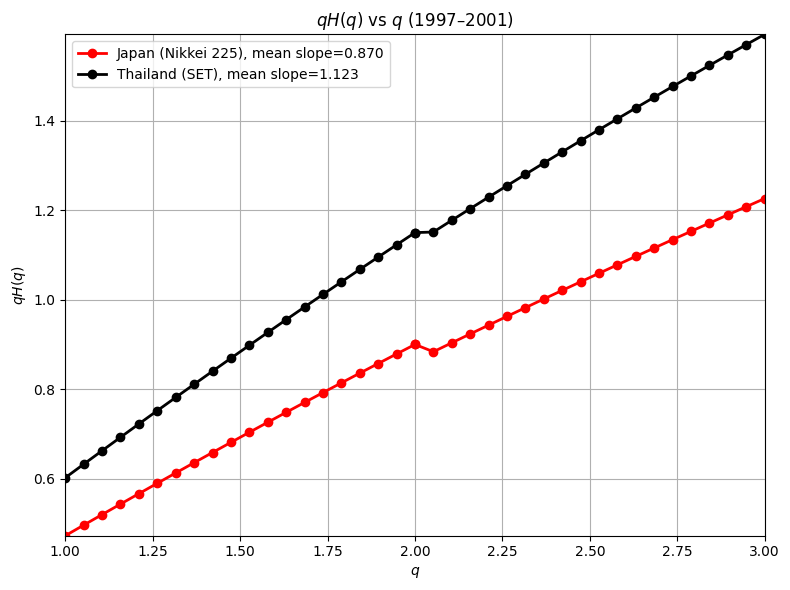

In [ ]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

start = "1997-01-01"
end   = "2001-12-31"

# q ranges
q_low  = np.linspace(1.0, 2.0, 20)
q_high = np.linspace(2.0, 3.0, 20)
qs = np.concatenate([q_low, q_high])

# tau ranges (q-dependent)
tau_low  = np.arange(1, 19)
tau_high = np.arange(1, 12)

markets = {
    "Japan (Nikkei 225)": ("^N225", "red"),
   "Thailand (SET)": ("^SET.BK", "black")
}

#markets = {
#    "Japan (JPY/USD)": ("JPYUSD=X", "red"),
#    "Thailand (THB/USD)": ("THBUSD=X", "black")
#}

#markets = {
#    "US Treasury 10Y": ("DGS10", "red"),
#    "Eurodollar 1Y": ("USD12MD156N", "black")
#}


# GHE estimator

def generalized_hurst_Kq(log_prices, q, taus):
    X = log_prices.values
    denom = np.mean(np.abs(X) ** q)
    Kq = []

    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Kq.append(np.mean(np.abs(diff) ** q) / denom)

    return np.array(Kq)

# Plot qH(q) vs q

plt.figure(figsize=(8, 6))

all_qHq = []

for label, (ticker, color) in markets.items():
    prices = yf.download(ticker, start=start, end=end)["Close"].dropna()
    log_prices = np.log10(prices)
    log_prices -= log_prices.mean()

    qHq = []

    for q in qs:
        taus = tau_low if q <= 2 else tau_high
        Kq = generalized_hurst_Kq(log_prices, q, taus)

        x = np.log10(taus)
        y = np.log10(Kq)

        slope, _, _, _, _ = linregress(x, y)
        qHq.append(slope)

    qHq = np.array(qHq)
    all_qHq.append(qHq)

    plt.plot(
        qs,
        qHq,
        marker="o",
        linewidth=2,
        color=color,
        label=f"{label}, mean slope={qHq.mean():.3f}"
    )


all_qHq = np.concatenate(all_qHq)

plt.xlim(qs.min(), qs.max())
plt.ylim(all_qHq.min(), all_qHq.max())

plt.xlabel(r"$q$")
plt.ylabel(r"$qH(q)$")
plt.title(r"$qH(q)$ vs $q$ (1997–2001)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
